In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA, PROC, OUT = "../data", "../data/processed", "../outputs"
os.makedirs(PROC, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
from dateutil import parser as dtparser
from sklearn.ensemble import RandomForestRegressor

In [2]:
train = pd.read_csv(f"{DATA}/train.csv")
test = pd.read_csv(f"{DATA}/test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (10886, 12) | test: (6493, 9)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  str    
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 1020.7 KB


In [4]:
print("Missing (train):", train.isna().sum().sum())
print("Missing (test): ", test.isna().sum().sum())
print("Duplicate rows (train):", train.duplicated().sum())
print("Duplicate timestamps (train):", train["datetime"].duplicated().sum())

Missing (train): 0
Missing (test):  0
Duplicate rows (train): 0
Duplicate timestamps (train): 0


In [ ]:
for df in (train, test):
    df["datetime"] = df["datetime"].apply(dtparser.parse)
train = train.sort_values("datetime").reset_index(drop=True)
test = test.sort_values("datetime").reset_index(drop=True)
print(train["datetime"].min(), "->", train["datetime"].max())
print(test["datetime"].min(), "->", test["datetime"].max())

2011-01-01 00:00:00 -> 2012-12-19 23:00:00
2011-01-20 00:00:00 -> 2012-12-31 23:00:00


In [6]:
for col in ["season", "holiday", "workingday", "weather"]:
    print(col, "-> train:", sorted(train[col].unique().tolist()), "| test:", sorted(test[col].unique().tolist()))
print()
print("Rows per weather type (train):")
print(train["weather"].value_counts().sort_index())

season -> train: [1, 2, 3, 4] | test: [1, 2, 3, 4]
holiday -> train: [0, 1] | test: [0, 1]
workingday -> train: [0, 1] | test: [0, 1]
weather -> train: [1, 2, 3, 4] | test: [1, 2, 3, 4]

Rows per weather type (train):
weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64


In [7]:
print("casual + registered == count for all rows:", bool((train["casual"] + train["registered"] == train["count"]).all()))

casual + registered == count for all rows: True


train: windspeed==0 -> 12.1% | humidity==0 -> 22 rows
test: windspeed==0 -> 13.4% | humidity==0 -> 0 rows


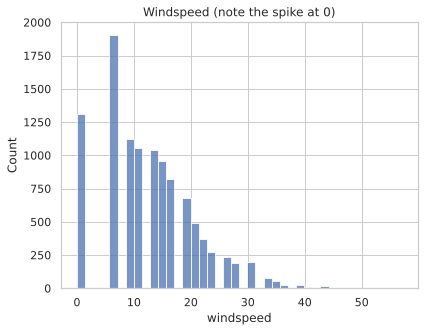

In [8]:
for df, name in [(train, "train"), (test, "test")]:
    print(f"{name}: windspeed==0 -> {(df['windspeed'] == 0).mean():.1%} | humidity==0 -> {(df['humidity'] == 0).sum()} rows")
sns.histplot(train["windspeed"], bins=40)
plt.title("Windspeed (note the spike at 0)")
plt.show()

In [9]:
both = pd.concat([train.assign(_src="train"), test.assign(_src="test")], ignore_index=True)
cols = ["season", "weather", "temp", "atemp", "humidity"]
known, unknown = both[both["windspeed"] > 0], both[both["windspeed"] == 0]

rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(known[cols], known["windspeed"])
both.loc[both["windspeed"] == 0, "windspeed"] = rf.predict(unknown[cols])

train["windspeed"] = both.loc[both["_src"] == "train", "windspeed"].values
test["windspeed"] = both.loc[both["_src"] == "test", "windspeed"].values
print("Zeros left -> train:", (train["windspeed"] == 0).sum(), "| test:", (test["windspeed"] == 0).sum())

Zeros left -> train: 0 | test: 0


Upper fence: 647 | rows above: 300 (2.8%)


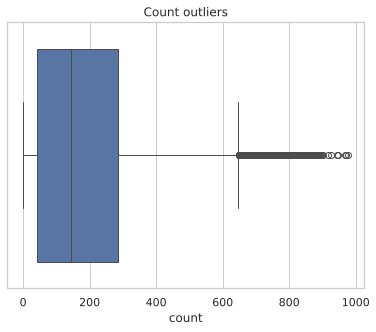

In [10]:
q1, q3 = train["count"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Upper fence: {upper:.0f} | rows above: {(train['count'] > upper).sum()} ({(train['count'] > upper).mean():.1%})")
sns.boxplot(x=train["count"])
plt.title("Count outliers")
plt.show()

In [11]:
train.to_csv(f"{PROC}/train_clean.csv", index=False)
test.to_csv(f"{PROC}/test_clean.csv", index=False)
print("Saved:", os.listdir(PROC))

Saved: ['test_clean.csv', 'train_clean.csv']
